In [8]:
# =========================================================
# CELL 1: SETUP & IMPORTS
# Purpose: install/import every library used downstream
# =========================================================
!pip -q install statsmodels scikit-learn openpyxl

import warnings, math, itertools
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu, kruskal

from sklearn.model_selection import (RepeatedStratifiedKFold, cross_validate,
                                     learning_curve, StratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              BaggingClassifier)
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (roc_auc_score, recall_score, confusion_matrix,
                             make_scorer, roc_curve)
from sklearn.decomposition import PCA

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RNG = 42
np.random.seed(RNG)
print("Setup complete.")

Setup complete.


In [9]:
# =========================================================
# CELL 2: LOAD DATA
# Purpose: upload 'Dean Dilemma.xlsx' and read 'Placement' sheet
# =========================================================
         # select Dean Dilemma.xlsx
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_excel("/content/drive/My Drive/PYTHON '26/Synthetic_Dean_Dilemma_65_35.xlsx")
# keep the name used by every downstream cell
df_raw = df.copy()
df_raw.columns = [str(c).strip() for c in df_raw.columns]

print("Shape:", df_raw.shape)
print("\nColumns:\n", list(df_raw.columns))
df_raw.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (5000, 26)

Columns:
 ['SlNo', 'Gender', 'Gender-B', 'Percent_SSC', 'Board_SSC', 'Board_CBSE', 'Board_ICSE', 'Percent_HSC', 'Board_HSC', 'Stream_HSC', 'Percent_Degree', 'Course_Degree', 'Degree_Engg', 'Experience_Yrs', 'Entrance_Test', 'S-TEST', 'Percentile_ET', 'Percent_MBA', 'S-TEST*SCORE', 'Specialization_MBA', 'Marks_Communication', 'Marks_Projectwork', 'Marks_BOCA', 'Placement', 'Placement_B', 'Salary']


,SlNo,Gender,Gender-B,Percent_SSC,Board_SSC,Board_CBSE,Board_ICSE,Percent_HSC,Board_HSC,Stream_HSC,Percent_Degree,Course_Degree,Degree_Engg,Experience_Yrs,Entrance_Test,S-TEST,Percentile_ET,Percent_MBA,S-TEST*SCORE,Specialization_MBA,Marks_Communication,Marks_Projectwork,Marks_BOCA,Placement,Placement_B,Salary
0,1,M,0,82.2,Others,0,0,77.0,ISC,Science,70.0,Management,0,0,NaN,0,0.00,62.46,0.00,Marketing & HR,57,73,68,Placed,1,275000
1,2,M,0,78.0,Others,0,0,78.0,Others,Science,78.6,Management,0,0,NaN,0,0.00,69.05,0.00,Marketing & HR,73,69,78,Placed,1,220000
2,3,M,0,61.6,ICSE,0,1,76.8,Others,Science,75.0,Computer Applications,0,0,NaN,0,0.00,66.59,0.00,Marketing & HR,62,60,64,Placed,1,240000
3,4,M,0,50.0,Others,0,0,57.0,Others,Science,57.1,Commerce,0,1,MAT,1,0.00,57.06,0.00,Marketing & IB,50,74,68,Placed,1,180000
4,5,F,1,54.0,Others,0,0,62.0,Others,Commerce,63.0,Arts,0,0,MAT,1,93.18,62.39,93.18,Marketing & HR,55,75,60,Placed,1,199000


In [10]:
# =========================================================
# CELL 3: DATA AUDIT
# =========================================================
d = df_raw.copy()

# --- tolerant column rename for common synthetic variants ---
RENAME = {
    "Placement_Status":"Placement", "PlacementStatus":"Placement",
    "SSC_Percent":"Percent_SSC",     "HSC_Percent":"Percent_HSC",
    "Degree_Percent":"Percent_Degree","Percentile":"Percentile_ET",
    "ET_Percentile":"Percentile_ET", "MBA_Percent":"Percent_MBA",
    "EntranceTest":"Entrance_Test",  "Specialization":"Specialization_MBA",
}
d = d.rename(columns={k:v for k,v in RENAME.items() if k in d.columns and v not in d.columns})

# --- required columns check ---
REQUIRED = ["Percent_SSC","Percent_HSC","Percent_Degree","Experience_Yrs",
            "Entrance_Test","Percentile_ET","Percent_MBA",
            "Marks_Communication","Marks_Projectwork","Marks_BOCA",
            "Specialization_MBA","Course_Degree","Stream_HSC","Board_SSC",
            "Gender","Placement","Salary"]
missing = [c for c in REQUIRED if c not in d.columns]
if missing:
    print("!! MISSING columns after rename:", missing)
    print("   Please add these mappings to RENAME in Cell 3 before continuing.")
else:
    print("All required columns present.")

# --- categorical clean ---
d["Placement"] = d["Placement"].astype(str).str.strip()
d["Gender"]    = d["Gender"].astype(str).str.strip()

# Entrance_Test: treat blank / "nan" / "None" as no-test
d["Entrance_Test"] = (
    d["Entrance_Test"].astype(str).str.strip()
      .replace({"": np.nan, "nan": np.nan, "None": np.nan, "none": np.nan})
)

# --- numeric coercion ---
num_cols = ["Percent_SSC","Percent_HSC","Percent_Degree","Experience_Yrs",
            "Percentile_ET","Percent_MBA","Marks_Communication",
            "Marks_Projectwork","Marks_BOCA","Salary"]
for c in num_cols:
    if c in d.columns:
        d[c] = pd.to_numeric(d[c], errors="coerce")

# --- flags ---
d["placed"]     = (d["Placement"] == "Placed").astype(int)
d["not_placed"] = 1 - d["placed"]
d["test_taken"] = d["Entrance_Test"].notna()

# --- consistency checks (guarded) ---
if "Placement_B" in d.columns:
    d["Placement_B"] = pd.to_numeric(d["Placement_B"], errors="coerce")
    match = (d["placed"].astype(float) == d["Placement_B"]).mean()
    print(f"Placement flag vs Placement_B agreement: {match:.4f}")
else:
    print("Placement_B not present (fine, skipping check).")

print("Unplaced rows with non-zero salary:",
      int(((d["placed"] == 0) & (d["Salary"] > 0)).sum()))
print("Placed rows with zero/NaN salary  :",
      int(((d["placed"] == 1) & ((d["Salary"].isna()) | (d["Salary"] <= 0))).sum()))

zero_pct = d[(d["test_taken"]) & (d["Percentile_ET"] == 0)]
print(f"\nTest-takers with Percentile_ET == 0 (treated as MISSING): {len(zero_pct)}")
if len(zero_pct):
    print(zero_pct[["Entrance_Test","Percentile_ET","Placement"]].head().to_string(index=False))

for c in ["Percent_SSC","Percent_HSC","Percent_Degree","Percentile_ET","Percent_MBA"]:
    if c in d.columns:
        bad = d[(d[c] < 0) | (d[c] > 100)].shape[0]
        print(f"{c}: out-of-[0,100] rows = {bad}")

print("\nOverall placement rate: %.4f" % d["placed"].mean())
print("Class counts:", d["placed"].value_counts().to_dict())

All required columns present.
Placement flag vs Placement_B agreement: 1.0000
Unplaced rows with non-zero salary: 0
Placed rows with zero/NaN salary  : 0

Test-takers with Percentile_ET == 0 (treated as MISSING): 815
Entrance_Test  Percentile_ET  Placement
          MAT            0.0     Placed
          MAT            0.0     Placed
          MAT            0.0     Placed
          CAT            0.0     Placed
          MAT            0.0 Not Placed
Percent_SSC: out-of-[0,100] rows = 0
Percent_HSC: out-of-[0,100] rows = 0
Percent_Degree: out-of-[0,100] rows = 0
Percentile_ET: out-of-[0,100] rows = 0
Percent_MBA: out-of-[0,100] rows = 0

Overall placement rate: 0.6500
Class counts: {1: 3250, 0: 1750}


In [11]:
# =========================================================
# CELL 4: CLEANING & FEATURES
# =========================================================
# drop duplicate flag columns if present
drop_cols = ["Gender-B","Placement_B","Board_CBSE","Board_ICSE",
             "Degree_Engg","S-TEST*SCORE","S-TEST"]
d = d.drop(columns=[c for c in drop_cols if c in d.columns])

# --- usable entrance score ---
d["usable_score"] = (
    d["test_taken"] & d["Percentile_ET"].notna() & (d["Percentile_ET"] > 0)
)
d["entrance_score"] = np.where(d["usable_score"], d["Percentile_ET"], np.nan)

# median of usable scores (safe fallback to 50 if none)
if d["usable_score"].any():
    med_score = d.loc[d["usable_score"], "Percentile_ET"].median()
else:
    med_score = 50.0
print("Median usable entrance score:", med_score)

d["entrance_score_filled"] = d["entrance_score"].fillna(med_score)
d["entrance_missing"]      = d["entrance_score"].isna().astype(int)

# --- test group ---
def test_group(r):
    if not r["test_taken"]:            return "No test"
    if pd.isna(r["entrance_score"]):   return "Missing score"
    if r["entrance_score"] < 50:       return "Below 50"
    if r["entrance_score"] < 75:       return "50-75"
    return "75+"
d["test_group"] = d.apply(test_group, axis=1)

# --- log salary ---
d["log_salary"] = np.where(
    (d["placed"] == 1) & (d["Salary"] > 0),
    np.log(d["Salary"]), np.nan
)

# --- gender flag ---
d["female"] = (d["Gender"] == "F").astype(int)

print("\nTest group counts:")
print(d["test_group"].value_counts(dropna=False))
print("\nPlaced:", int(d["placed"].sum()), "| Not Placed:", int(d["not_placed"].sum()))
print("Median salary (placed):", d.loc[d["placed"]==1, "Salary"].median())
print("Max salary (placed):",    d.loc[d["placed"]==1, "Salary"].max())

Median usable entrance score: 66.0

Test group counts:
test_group
50-75            1626
75+              1138
No test           883
Missing score     815
Below 50          538
Name: count, dtype: int64

Placed: 3250 | Not Placed: 1750
Median salary (placed): 260000.0
Max salary (placed): 924000


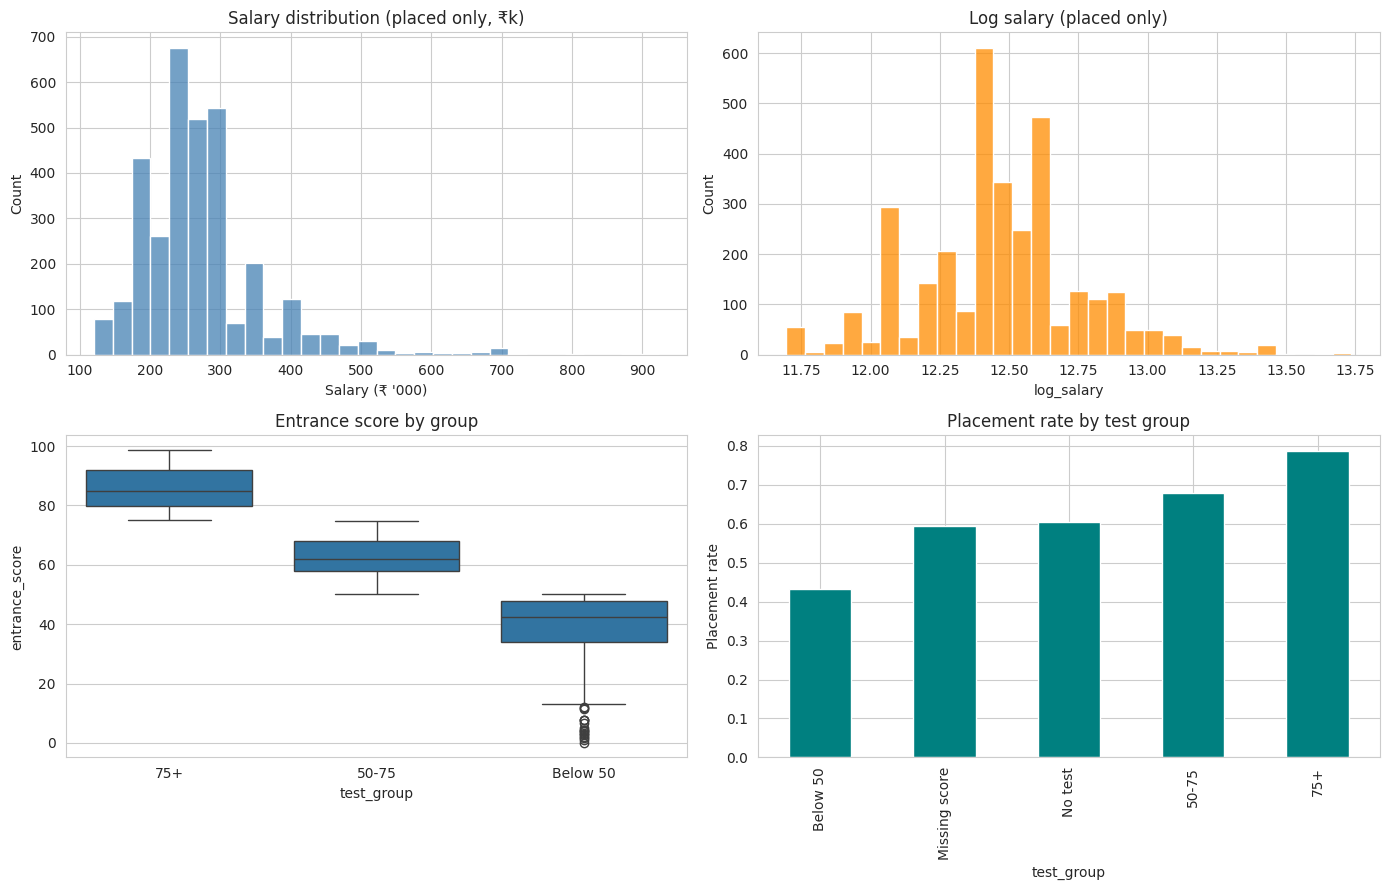

In [12]:
# =========================================================
# CELL 5: EDA — distributions and placement by key groups
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sal_placed = d.loc[d["placed"] == 1, "Salary"].dropna()
if len(sal_placed):
    sns.histplot(sal_placed/1000, bins=30, ax=axes[0,0], color="steelblue")
axes[0,0].set_title("Salary distribution (placed only, ₹k)")
axes[0,0].set_xlabel("Salary (₹ '000)")

sns.histplot(d.loc[d["placed"]==1, "log_salary"].dropna(), bins=30,
             ax=axes[0,1], color="darkorange")
axes[0,1].set_title("Log salary (placed only)")

sns.boxplot(data=d.dropna(subset=["entrance_score"]),
            x="test_group", y="entrance_score", ax=axes[1,0])
axes[1,0].set_title("Entrance score by group")

grp_rate = d.groupby("test_group")["placed"].mean().sort_values()
grp_rate.plot(kind="bar", ax=axes[1,1], color="teal")
axes[1,1].set_title("Placement rate by test group")
axes[1,1].set_ylabel("Placement rate")

plt.tight_layout(); plt.show()

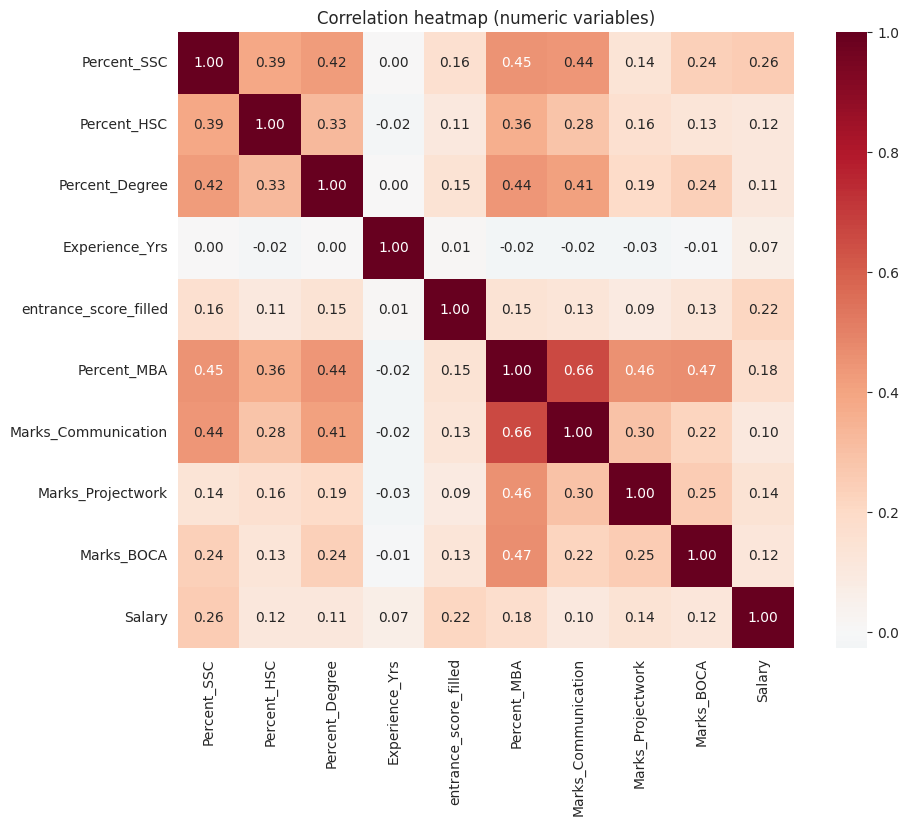


--- Chi-square: placement vs categorical ---
Gender                 chi2= 18.796  p=0.0000
Board_SSC              chi2= 16.867  p=0.0002
Stream_HSC             chi2= 19.514  p=0.0001
Course_Degree          chi2= 27.368  p=0.0001
Specialization_MBA     chi2= 10.910  p=0.0043
test_group             chi2=231.265  p=0.0000

--- Numeric differences: Placed vs Not Placed ---
Percent_SSC            t-test p=0.0000   MW p=0.0000
Percent_HSC            t-test p=0.0000   MW p=0.0000
Percent_Degree         t-test p=0.0000   MW p=0.0027
Experience_Yrs         t-test p=0.0000   MW p=0.0000
entrance_score_filled  t-test p=0.0000   MW p=0.0000
Percent_MBA            t-test p=0.0000   MW p=0.0000
Marks_Communication    t-test p=0.1809   MW p=0.8078
Marks_Projectwork      t-test p=0.0000   MW p=0.0000
Marks_BOCA             t-test p=0.0000   MW p=0.0000


In [13]:
# =========================================================
# CELL 6: CORRELATIONS + GROUP DIFFERENCE TESTS
# =========================================================
num_vars = ["Percent_SSC","Percent_HSC","Percent_Degree","Experience_Yrs",
            "entrance_score_filled","Percent_MBA","Marks_Communication",
            "Marks_Projectwork","Marks_BOCA","Salary"]
num_vars = [c for c in num_vars if c in d.columns]
corr = d[num_vars].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation heatmap (numeric variables)"); plt.show()

# chi-square placement vs categoricals
cat_vars = ["Gender","Board_SSC","Stream_HSC","Course_Degree",
            "Specialization_MBA","test_group"]
print("\n--- Chi-square: placement vs categorical ---")
for c in cat_vars:
    if c not in d.columns: continue
    tab = pd.crosstab(d[c], d["placed"])
    tab = tab[(tab.sum(axis=1) > 0)]
    tab = tab.loc[:, tab.sum(axis=0) > 0]
    if tab.shape[0] < 2 or tab.shape[1] < 2:
        print(f"{c:22s} skipped (only one level present)"); continue
    chi2, p, dof, exp = chi2_contingency(tab)
    flag = "  <-- thin cells" if (exp < 5).any() else ""
    print(f"{c:22s} chi2={chi2:7.3f}  p={p:.4f}{flag}")

# t-test / Mann-Whitney for numeric by placement
print("\n--- Numeric differences: Placed vs Not Placed ---")
for c in ["Percent_SSC","Percent_HSC","Percent_Degree","Experience_Yrs",
          "entrance_score_filled","Percent_MBA","Marks_Communication",
          "Marks_Projectwork","Marks_BOCA"]:
    if c not in d.columns: continue
    a = d.loc[d["placed"]==1, c].dropna()
    b = d.loc[d["placed"]==0, c].dropna()
    if len(a) > 1 and len(b) > 1:
        _, p_t = ttest_ind(a, b, equal_var=False)
        _, p_m = mannwhitneyu(a, b, alternative="two-sided")
        print(f"{c:22s} t-test p={p_t:.4f}   MW p={p_m:.4f}")

In [14]:
# =========================================================
# CELL 7: RQ1 — Entrance test mandatory?
# =========================================================
def boot_median_ci(x, n_boot=2000, alpha=0.05):
    x = np.asarray(x, float)
    if len(x) == 0: return (np.nan, np.nan)
    boots = np.array([np.median(np.random.choice(x, len(x), replace=True))
                      for _ in range(n_boot)])
    return tuple(np.percentile(boots, [100*alpha/2, 100*(1-alpha/2)]))

# (a) descriptive by group
order = ["75+","50-75","Below 50","No test","Missing score"]
rows = []
for g in order:
    sub = d[d["test_group"] == g]
    n = len(sub)
    if n == 0: continue
    k = int(sub["placed"].sum())
    lo, hi = proportion_confint(k, n, method="wilson")
    sal = sub.loc[sub["placed"] == 1, "Salary"].dropna()
    med_lo, med_hi = boot_median_ci(sal) if len(sal) else (np.nan, np.nan)
    rows.append({"group": g, "n": n, "placed": k,
                 "placement_rate": k/n, "rate_lo": lo, "rate_hi": hi,
                 "median_salary": sal.median() if len(sal) else np.nan,
                 "med_lo": med_lo, "med_hi": med_hi})
rq1_desc = pd.DataFrame(rows)
print("RQ1 — Group descriptives (95% Wilson CI on placement rate)")
print(rq1_desc.round(4).to_string(index=False))

# (b) logistic regression controlling for SSC %, degree %, experience
present_cats = [c for c in order if (d["test_group"] == c).any()]
if len(present_cats) >= 2:
    d["grp_cat"] = pd.Categorical(d["test_group"], categories=present_cats)
    X = pd.get_dummies(d["grp_cat"], prefix="grp", drop_first=True).astype(float)
    X["Percent_SSC"]    = d["Percent_SSC"].astype(float)
    X["Percent_Degree"] = d["Percent_Degree"].astype(float)
    X["Experience_Yrs"] = d["Experience_Yrs"].astype(float)
    X = sm.add_constant(X.fillna(X.median()))
    y = d["placed"]
    try:
        m_rq1 = sm.Logit(y, X).fit(disp=0)
        or_tab = pd.DataFrame({
            "coef": m_rq1.params,
            "OR":   np.exp(m_rq1.params),
            "OR_lo":np.exp(m_rq1.conf_int()[0]),
            "OR_hi":np.exp(m_rq1.conf_int()[1]),
            "p":    m_rq1.pvalues
        }).round(4)
        print(f"\nRQ1 — Logistic regression (ref group = '{present_cats[0]}')")
        print(or_tab.to_string())
    except Exception as e:
        print("RQ1 logit failed:", e)

    print("\nINTERPRETATION")
    print("• If 'Below 50' OR < 1 and p < .05 and the group trails others by ≥10 pts -> minimum percentile justified.")
    print("• If 'No test' OR not significantly < 1 -> test need NOT be mandatory.")
else:
    print("RQ1 logistic skipped: fewer than 2 test groups present.")

RQ1 — Group descriptives (95% Wilson CI on placement rate)
        group    n  placed  placement_rate  rate_lo  rate_hi  median_salary   med_lo   med_hi
          75+ 1138     896          0.7873   0.7626   0.8101       270000.0 265000.0 275000.0
        50-75 1626    1104          0.6790   0.6559   0.7012       260000.0 252000.0 265000.0
     Below 50  538     233          0.4331   0.3918   0.4753       250000.0 240000.0 252200.0
      No test  883     533          0.6036   0.5710   0.6354       260000.0 250000.0 265000.0
Missing score  815     484          0.5939   0.5598   0.6271       250000.0 243000.0 250000.0

RQ1 — Logistic regression (ref group = '75+')
                     coef      OR   OR_lo   OR_hi       p
const             -0.7392  0.4775  0.2787  0.8181  0.0071
grp_50-75         -0.4913  0.6118  0.5110  0.7326  0.0000
grp_Below 50      -1.4436  0.2361  0.1879  0.2966  0.0000
grp_No test       -0.7986  0.4500  0.3683  0.5498  0.0000
grp_Missing score -0.7701  0.4630  0.376

In [15]:
# =========================================================
# CELL 8: RQ2 — Which academic variables matter?
# =========================================================
feat = ["Percent_SSC","Percent_HSC","Percent_Degree",
        "Experience_Yrs","entrance_score_filled"]
feat = [c for c in feat if c in d.columns]

# --- standardized logistic (placement) ---
X = d[feat].copy()
Xs = (X - X.mean()) / X.std(ddof=0).replace(0, np.nan)
Xs = Xs.fillna(0)  # safe if a column is constant
if d["entrance_missing"].nunique() > 1:
    Xs["entrance_missing"] = d["entrance_missing"].astype(float)
Xs = sm.add_constant(Xs)
y = d["placed"]

try:
    m_logit = sm.Logit(y, Xs).fit(disp=0)
    logit_tab = pd.DataFrame({
        "std_coef": m_logit.params,
        "OR_per_1SD": np.exp(m_logit.params),
        "p": m_logit.pvalues
    }).round(4)
    print("RQ2 — Standardized LOGISTIC (placement)")
    print(logit_tab.to_string())
except Exception as e:
    print("RQ2 logit failed:", e)
    logit_tab = pd.DataFrame()

# --- standardized OLS on log salary (placed only) ---
pl = d[d["placed"] == 1].dropna(subset=["log_salary"]).copy()
Xp = pl[feat].copy()
Xps = (Xp - Xp.mean()) / Xp.std(ddof=0).replace(0, np.nan)
Xps = Xps.fillna(0)
if pl["entrance_missing"].nunique() > 1:
    Xps["entrance_missing"] = pl["entrance_missing"].astype(float)
Xps = sm.add_constant(Xps)

try:
    m_ols = sm.OLS(pl["log_salary"], Xps).fit()
    ols_tab = pd.DataFrame({
        "std_coef": m_ols.params,
        "t": m_ols.tvalues,
        "p": m_ols.pvalues,
        "ci_lo": m_ols.conf_int()[0],
        "ci_hi": m_ols.conf_int()[1]
    }).round(4)
    print(f"\nRQ2 — Standardized OLS on log salary (placed, n={len(pl)})")
    print(ols_tab.to_string())
    print(f"\nR² = {m_ols.rsquared:.3f}")
except Exception as e:
    print("RQ2 OLS failed:", e)
    ols_tab = pd.DataFrame()

# --- VIF ---
try:
    Xv = Xps.drop(columns="const")
    Xv = Xv.loc[:, Xv.std() > 0]  # drop constant columns
    if Xv.shape[1] >= 2:
        vif = pd.DataFrame({
            "variable": Xv.columns,
            "VIF": [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]
        }).round(3)
        print("\nVIF (multicollinearity):")
        print(vif.to_string(index=False))
except Exception as e:
    print("VIF skipped:", e)

print("\nINTERPRETATION")
print("• Keep only features whose standardized coefficient stays significant (p < .05).")

RQ2 — Standardized LOGISTIC (placement)
                       std_coef  OR_per_1SD       p
const                    0.7833      2.1886  0.0000
Percent_SSC              0.4521      1.5716  0.0000
Percent_HSC             -0.0357      0.9650  0.2993
Percent_Degree          -0.0951      0.9093  0.0070
Experience_Yrs           0.1786      1.1956  0.0000
entrance_score_filled    0.3897      1.4766  0.0000
entrance_missing        -0.3003      0.7406  0.0000

RQ2 — Standardized OLS on log salary (placed, n=3250)
                       std_coef          t       p    ci_lo    ci_hi
const                   12.4757  2046.8621  0.0000  12.4637  12.4876
Percent_SSC              0.0434     7.6059  0.0000   0.0322   0.0546
Percent_HSC              0.0271     4.9825  0.0000   0.0165   0.0378
Percent_Degree           0.0072     1.2724  0.2033  -0.0039   0.0183
Experience_Yrs           0.0024     0.4820  0.6299  -0.0074   0.0123
entrance_score_filled    0.0259     5.0506  0.0000   0.0158   0.0359
entran

ENTRANCE PERCENTILE — cutoff curve
 cutoff  retained  share_retained  placement_rate
      0      3302          1.0000          0.6763
      5      3292          0.9970          0.6768
     10      3287          0.9955          0.6769
     15      3270          0.9903          0.6761
     20      3263          0.9882          0.6770
     25      3223          0.9761          0.6832
     30      3199          0.9688          0.6843
     35      3132          0.9485          0.6909
     40      3080          0.9328          0.6951
     45      2966          0.8982          0.6979
     50      2764          0.8371          0.7236
     55      2593          0.7853          0.7339
     60      2197          0.6654          0.7519
     65      1730          0.5239          0.7850
     70      1453          0.4400          0.7639
     75      1138          0.3446          0.7873
     80       853          0.2583          0.7937
     85       586          0.1775          0.7918
     90       3

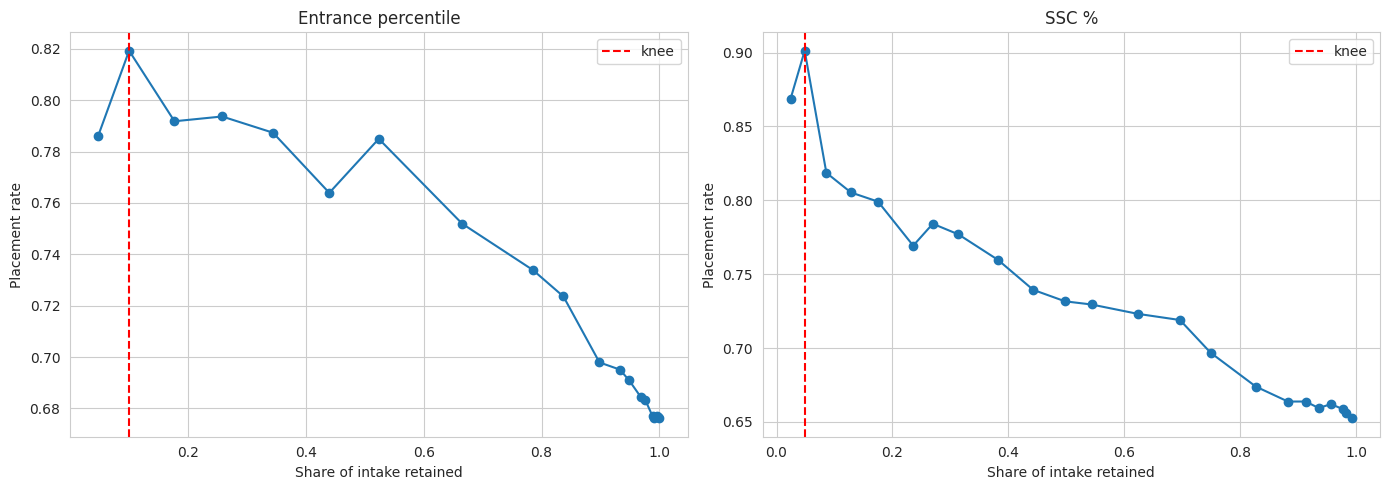


Entrance: placement points gained per 1% intake lost
 cutoff  retained  share_retained  placement_rate  d_retention  d_placement  pts_per_1pct_lost
      5      3292          0.9970          0.6768       0.0030       0.0005             0.0018
     10      3287          0.9955          0.6769       0.0015       0.0001             0.0008
     15      3270          0.9903          0.6761       0.0051      -0.0008            -0.0015
     20      3263          0.9882          0.6770       0.0021       0.0008             0.0040
     25      3223          0.9761          0.6832       0.0121       0.0062             0.0051
     30      3199          0.9688          0.6843       0.0073       0.0011             0.0015
     35      3132          0.9485          0.6909       0.0203       0.0067             0.0033
     40      3080          0.9328          0.6951       0.0157       0.0042             0.0027
     45      2966          0.8982          0.6979       0.0345       0.0028             0.0

In [16]:
# =========================================================
# CELL 9: RQ3 — cutoff curves for Entrance %ile and SSC %
# =========================================================
def find_knee(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    if len(x) < 3: return 0
    xn = (x - x.min()) / (x.max() - x.min() + 1e-12)
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    return int(np.argmax(yn - xn))

# --- Entrance percentile (usable scores only) ---
rows_e = []
for t in np.arange(0, 96, 5):
    mask = d["usable_score"] & (d["entrance_score"] >= t)
    if mask.sum() == 0: continue
    rows_e.append({"cutoff": t, "retained": int(mask.sum()),
                   "share_retained": mask.sum() / max(d["usable_score"].sum(), 1),
                   "placement_rate": d.loc[mask, "placed"].mean()})
curve_e = pd.DataFrame(rows_e)

if len(curve_e) >= 3:
    k_e = find_knee(curve_e["share_retained"], curve_e["placement_rate"])
    print("ENTRANCE PERCENTILE — cutoff curve")
    print(curve_e.round(4).to_string(index=False))
    print("Knee: cutoff = %d | keeps %.1f%% at %.1f%% placement"
          % (curve_e.iloc[k_e]["cutoff"],
             100*curve_e.iloc[k_e]["share_retained"],
             100*curve_e.iloc[k_e]["placement_rate"]))
else:
    k_e = 0
    print("Not enough entrance-percentile variation for RQ3 curve.")

# --- SSC % ---
rows_s = []
for t in np.arange(40, 86, 2):
    mask = d["Percent_SSC"] >= t
    if mask.sum() == 0: continue
    rows_s.append({"cutoff": t, "retained": int(mask.sum()),
                   "share_retained": mask.sum() / len(d),
                   "placement_rate": d.loc[mask, "placed"].mean()})
curve_s = pd.DataFrame(rows_s)

if len(curve_s) >= 3:
    k_s = find_knee(curve_s["share_retained"], curve_s["placement_rate"])
    print("\nSSC PERCENT — cutoff curve")
    print(curve_s.round(4).to_string(index=False))
    print("Knee: cutoff = %d | keeps %.1f%% at %.1f%% placement"
          % (curve_s.iloc[k_s]["cutoff"],
             100*curve_s.iloc[k_s]["share_retained"],
             100*curve_s.iloc[k_s]["placement_rate"]))
else:
    k_s = 0
    print("Not enough SSC variation for RQ3 curve.")

# --- plots ---
if len(curve_e) >= 3 and len(curve_s) >= 3:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, cur, k, title in [(axes[0], curve_e, k_e, "Entrance percentile"),
                              (axes[1], curve_s, k_s, "SSC %")]:
        ax.plot(cur["share_retained"], cur["placement_rate"], marker="o")
        ax.axvline(cur.iloc[k]["share_retained"], color="red", ls="--", label="knee")
        ax.set_xlabel("Share of intake retained"); ax.set_ylabel("Placement rate")
        ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.show()

# --- cost-per-point table ---
def marginal_gain(cur):
    c = cur.copy()
    c["d_retention"] = -c["share_retained"].diff()
    c["d_placement"] =  c["placement_rate"].diff()
    c["pts_per_1pct_lost"] = c["d_placement"] / (c["d_retention"] * 100)
    return c
if len(curve_e) >= 3:
    print("\nEntrance: placement points gained per 1% intake lost")
    print(marginal_gain(curve_e).dropna().round(4).to_string(index=False))

In [17]:
# =========================================================
# CELL 10: RQ6 — salary gap: profile or residual?
# =========================================================
pl = d[d["placed"] == 1].dropna(subset=["log_salary"]).copy()

n_m = (pl["Gender"] == "M").sum(); n_f = (pl["Gender"] == "F").sum()
print(f"Placed sample: M={n_m}, F={n_f}")

if n_m > 1 and n_f > 1:
    # (a) raw gap
    m_sal = pl.loc[pl["Gender"]=="M", "Salary"]
    f_sal = pl.loc[pl["Gender"]=="F", "Salary"]
    t, p = ttest_ind(m_sal, f_sal, equal_var=False)
    print("Raw salary  M: %.0f | F: %.0f | gap: %.0f | t-test p = %.4f"
          % (m_sal.mean(), f_sal.mean(), m_sal.mean()-f_sal.mean(), p))

    # (b) OLS log salary with/without controls
    try:
        base = smf.ols("log_salary ~ female", data=pl).fit()
        ctrl = smf.ols("log_salary ~ female + Experience_Yrs + entrance_score_filled "
                       "+ Percent_SSC + Percent_Degree + C(Specialization_MBA)",
                       data=pl).fit()
        print("\nModel 1 (no controls): female coef = %.4f  (p=%.4f)"
              % (base.params["female"], base.pvalues["female"]))
        print("Model 2 (with controls): female coef = %.4f  (p=%.4f)"
              % (ctrl.params["female"], ctrl.pvalues["female"]))
    except Exception as e:
        print("OLS comparison skipped:", e)

    # (c) Neumark decomposition (pooled coefficients)
    try:
        dum = pd.get_dummies(pl[["Specialization_MBA","Course_Degree"]],
                             drop_first=True).astype(float)
        Xd = pd.concat([pl[["female","Experience_Yrs","entrance_score_filled",
                            "Percent_SSC","Percent_Degree"]], dum], axis=1).astype(float)
        Xd = sm.add_constant(Xd.fillna(Xd.median()))
        pooled = sm.OLS(pl["log_salary"], Xd).fit()

        gap = (pl.loc[pl["female"]==0, "log_salary"].mean()
               - pl.loc[pl["female"]==1, "log_salary"].mean())
        Xm = Xd[pl["female"]==0].mean()
        Xf = Xd[pl["female"]==1].mean()
        explained   = float(((Xm - Xf) * pooled.params).sum())
        unexplained = gap - explained
        print("\nLog-salary gap (M−F): %.4f  (~%.1f%%)"
              % (gap, 100*(np.exp(gap)-1)))
        if abs(gap) > 1e-9:
            print("Explained by profile : %.4f (%.1f%%)"
                  % (explained, 100*explained/gap))
            print("Unexplained (residual): %.4f (%.1f%%)"
                  % (unexplained, 100*unexplained/gap))
    except Exception as e:
        print("Decomposition skipped:", e)
else:
    print("RQ6 skipped: not enough of one gender in the placed sample.")

# placement rates on FULL sample (was a bug in original — used placed-only)
print("\nPlacement rate by gender (full sample):",
      d.groupby("Gender")["placed"].mean().round(3).to_dict())

print("\nInterpretation: if female coef in Model 2 shrinks to noise,")
print("the lever is seat/recruiter mix; if it stays, it's a placement-cell issue.")
print("Gender is NEVER an admission criterion either way.")

Placed sample: M=2241, F=1009
Raw salary  M: 271315 | F: 273687 | gap: -2371 | t-test p = 0.4762

Model 1 (no controls): female coef = 0.0086  (p=0.4434)
Model 2 (with controls): female coef = 0.0103  (p=0.3464)

Log-salary gap (M−F): -0.0086  (~-0.9%)
Explained by profile : -0.0086 (100.0%)
Unexplained (residual): 0.0000 (-0.0%)

Placement rate by gender (full sample): {'F': 0.608, 'M': 0.671}

Interpretation: if female coef in Model 2 shrinks to noise,
the lever is seat/recruiter mix; if it stays, it's a placement-cell issue.
Gender is NEVER an admission criterion either way.


Feature matrix: (5000, 19) | Not Placed rate = 0.350
Baseline (predict majority='Placed'): accuracy=65.0%, AUC=0.50, recall(Not Placed)=0.00

RQ7 — 5×5 repeated stratified CV
              model  auc_mean  auc_sd  recall_np_mean  recall_np_sd
Baseline (majority)     0.500   0.000           0.000         0.000
           Logistic     0.679   0.013           0.256         0.021
    Bagging (trees)     0.775   0.010           0.348         0.037
      Random Forest     0.807   0.010           0.422         0.018
  Gradient Boosting     0.829   0.011           0.444         0.020

Decision rule: build early-warning only if AUC >> 0.5 AND recall on Not Placed is meaningful.


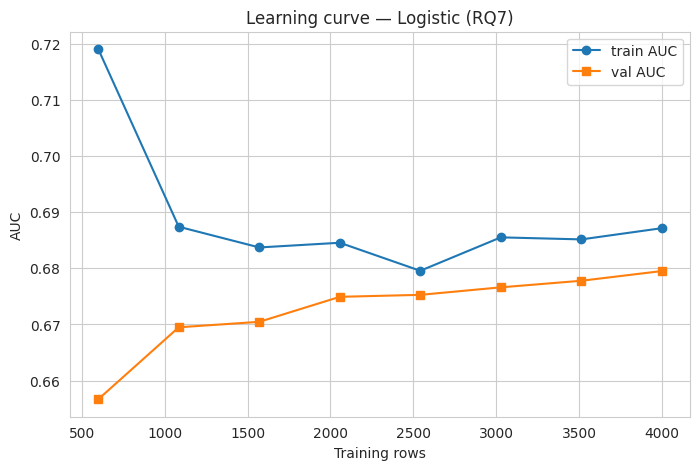

In [18]:
# =========================================================
# CELL 11: RQ7 — can we predict Not Placed from admission data?
# =========================================================
feat_cols = ["Percent_SSC","Percent_HSC","Percent_Degree","Experience_Yrs",
             "entrance_score_filled","entrance_missing","female"]
feat_cols = [c for c in feat_cols if c in d.columns]
Xp = d[feat_cols].copy()

for c in ["Specialization_MBA","Stream_HSC","Board_SSC","Course_Degree"]:
    if c in d.columns:
        Xp = pd.concat([Xp, pd.get_dummies(d[c], prefix=c, drop_first=True).astype(float)],
                       axis=1)

Xp = Xp.astype(float)
Xp = Xp.loc[:, Xp.notna().any()]   # drop entirely-NaN columns
Xp = Xp.fillna(Xp.median())

y = d["not_placed"].values
print("Feature matrix:", Xp.shape, "| Not Placed rate = %.3f" % y.mean())

# dynamic majority-class baseline
majority_class = 1 if y.mean() > 0.5 else 0  # 1 = Not Placed
baseline_acc   = max(y.mean(), 1-y.mean())
baseline_recall_np = 1.0 if majority_class == 1 else 0.0
print(f"Baseline (predict majority='{'Not Placed' if majority_class else 'Placed'}'): "
      f"accuracy={baseline_acc:.1%}, AUC=0.50, recall(Not Placed)={baseline_recall_np:.2f}")

def auc_scorer(est, X, y):
    return roc_auc_score(y, est.predict_proba(X)[:, 1])
recall_np = make_scorer(recall_score, pos_label=1)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RNG)

models = {
    "Baseline (majority)": None,
    "Logistic": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc",  StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=RNG))]),
    "Bagging (trees)": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", BaggingClassifier(
            DecisionTreeClassifier(max_depth=5, random_state=RNG),
            n_estimators=200, random_state=RNG, n_jobs=-1))]),
    "Random Forest": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=400, min_samples_leaf=3,
            random_state=RNG, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", GradientBoostingClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=2,
            subsample=0.8, random_state=RNG))]),
}

results = [{"model":"Baseline (majority)",
            "auc_mean":0.500, "auc_sd":0.0,
            "recall_np_mean":baseline_recall_np, "recall_np_sd":0.0}]
for name, mdl in models.items():
    if mdl is None: continue
    try:
        cvres = cross_validate(mdl, Xp, y, cv=cv,
                               scoring={"auc":auc_scorer, "recall_np":recall_np},
                               n_jobs=-1)
        results.append({"model":name,
                        "auc_mean":cvres["test_auc"].mean(),
                        "auc_sd":cvres["test_auc"].std(),
                        "recall_np_mean":cvres["test_recall_np"].mean(),
                        "recall_np_sd":cvres["test_recall_np"].std()})
    except Exception as e:
        print(f"{name} failed:", e)

rq7_tab = pd.DataFrame(results).round(3)
print("\nRQ7 — 5×5 repeated stratified CV")
print(rq7_tab.to_string(index=False))
print("\nDecision rule: build early-warning only if AUC >> 0.5 AND recall on Not Placed is meaningful.")

# learning curve
try:
    train_sizes, train_sc, val_sc = learning_curve(
        models["Logistic"], Xp, y,
        cv=StratifiedKFold(5, shuffle=True, random_state=RNG),
        scoring=auc_scorer, train_sizes=np.linspace(0.15, 1.0, 8), n_jobs=-1)
    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_sc.mean(1), "o-", label="train AUC")
    plt.plot(train_sizes, val_sc.mean(1),  "s-", label="val AUC")
    plt.xlabel("Training rows"); plt.ylabel("AUC"); plt.legend()
    plt.title("Learning curve — Logistic (RQ7)"); plt.show()
except Exception as e:
    print("Learning curve skipped:", e)

Segmentation (KMeans, k=4) — profile + outcome
            n  placement_rate  median_salary  mean_SSC  mean_degree  mean_entrance  mean_experience
segment                                                                                            
0        1669           0.741       275000.0    73.414       69.540         72.185            0.357
1         496           0.450       250000.0    61.636       60.919         38.366            0.292
2        1649           0.590       250000.0    58.454       58.571         68.181            0.000
3        1186           0.689       251000.0    59.688       59.433         67.361            1.306

Decision tree rules (max_depth=3):
|--- Percent_HSC <= 46.95
|   |--- entrance_score_filled <= 67.10
|   |   |--- Percent_Degree <= 54.60
|   |   |   |--- class: 0
|   |   |--- Percent_Degree >  54.60
|   |   |   |--- class: 0
|   |--- entrance_score_filled >  67.10
|   |   |--- Percent_HSC <= 45.05
|   |   |   |--- class: 1
|   |   |--- Percent_HSC 

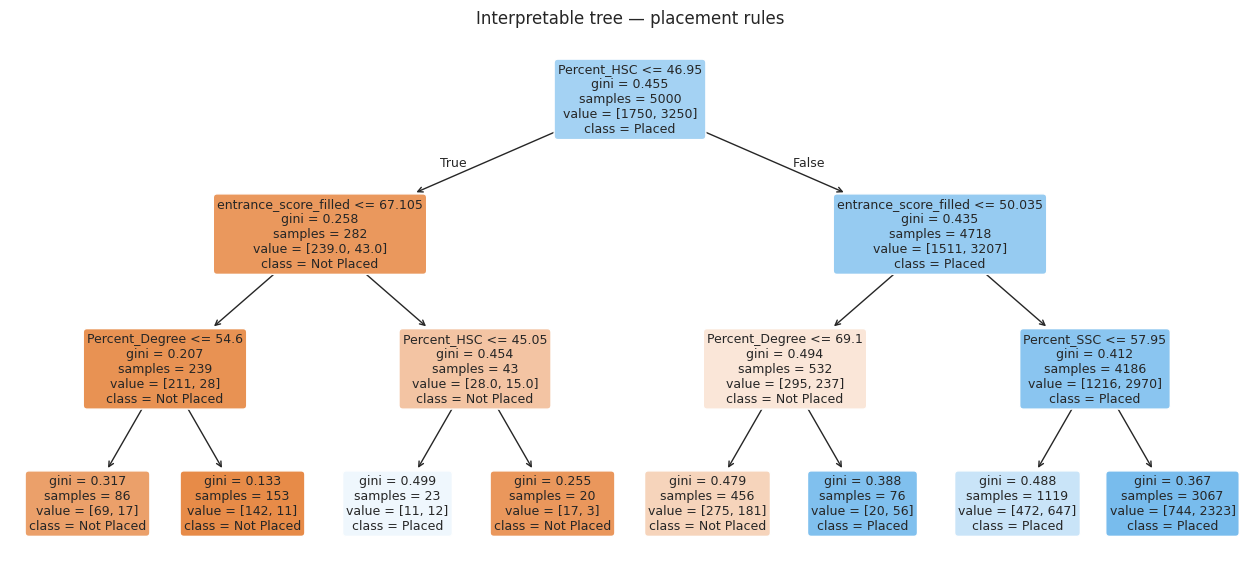

In [19]:
# =========================================================
# CELL 12: SEGMENTATION + DECISION TREE
# =========================================================
seg_feats = ["Percent_SSC","Percent_Degree","entrance_score_filled",
             "Experience_Yrs","Percent_MBA"]
seg_feats = [c for c in seg_feats if c in d.columns]
Xs = d[seg_feats].copy().fillna(d[seg_feats].median())
Xs_std = StandardScaler().fit_transform(Xs)

km = KMeans(n_clusters=4, n_init=20, random_state=RNG)
d["segment"] = km.fit_predict(Xs_std)

seg = d.groupby("segment").agg(
    n=("placed","size"),
    placement_rate=("placed","mean"),
    median_salary=("Salary", lambda s: s[s > 0].median() if (s > 0).any() else np.nan),
    mean_SSC=("Percent_SSC","mean"),
    mean_degree=("Percent_Degree","mean"),
    mean_entrance=("entrance_score_filled","mean"),
    mean_experience=("Experience_Yrs","mean")
).round(3)
print("Segmentation (KMeans, k=4) — profile + outcome")
print(seg.to_string())

# decision tree rules on placement
try:
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=RNG)
    tree.fit(Xp, d["placed"])
    print("\nDecision tree rules (max_depth=3):")
    print(export_text(tree, feature_names=list(Xp.columns), decimals=2))

    plt.figure(figsize=(16, 7))
    plot_tree(tree, feature_names=list(Xp.columns),
              class_names=["Not Placed","Placed"],
              filled=True, rounded=True, fontsize=9)
    plt.title("Interpretable tree — placement rules")
    plt.show()
except Exception as e:
    print("Decision tree skipped:", e)

In [20]:
# =========================================================
# CELL 13: ROBUSTNESS
# =========================================================
pl = d[d["placed"] == 1].dropna(subset=["log_salary"]).copy()

# (a) bootstrap CI on raw salary gap
if (pl["Gender"] == "M").sum() > 1 and (pl["Gender"] == "F").sum() > 1:
    def boot_gap(n_boot=1000):
        gaps = []
        for _ in range(n_boot):
            s = pl.sample(len(pl), replace=True)
            m = s.loc[s["Gender"]=="M", "Salary"]
            f = s.loc[s["Gender"]=="F", "Salary"]
            if len(m) and len(f):
                gaps.append(m.mean() - f.mean())
        return np.percentile(gaps, [2.5, 97.5]) if gaps else (np.nan, np.nan)
    lo, hi = boot_gap()
    print("Bootstrap 95%% CI on raw salary gap (M−F): [₹%.0f, ₹%.0f]" % (lo, hi))

# (b) RQ1 logistic excluding missing-score students
d2 = d[d["test_group"] != "Missing score"].copy()
present = [c for c in ["75+","50-75","Below 50","No test"]
           if (d2["test_group"] == c).any()]
if len(present) >= 2:
    d2["grp_cat"] = pd.Categorical(d2["test_group"], categories=present)
    X2 = pd.get_dummies(d2["grp_cat"], prefix="grp", drop_first=True).astype(float)
    X2["Percent_SSC"]    = d2["Percent_SSC"].astype(float)
    X2["Percent_Degree"] = d2["Percent_Degree"].astype(float)
    X2["Experience_Yrs"] = d2["Experience_Yrs"].astype(float)
    X2 = sm.add_constant(X2.fillna(X2.median()))
    try:
        m2 = sm.Logit(d2["placed"], X2).fit(disp=0)
        print("\nRQ1 logistic (excluding missing-score):")
        print(pd.DataFrame({"OR": np.exp(m2.params), "p": m2.pvalues}).round(3).to_string())
    except Exception as e:
        print("RQ1 robustness skipped:", e)

# (c) salary OLS excluding > ₹4.5L outliers
pl2 = pl[pl["Salary"] <= 450000].copy()
try:
    ols2 = smf.ols("log_salary ~ female + Experience_Yrs + entrance_score_filled "
                   "+ Percent_SSC + Percent_Degree + C(Specialization_MBA)",
                   data=pl2).fit()
    print("\nGender coef in salary OLS (salary ≤ ₹4.5L): %.4f (p=%.4f)"
          % (ols2.params["female"], ols2.pvalues["female"]))
except Exception as e:
    print("Outlier-robust OLS skipped:", e)

Bootstrap 95% CI on raw salary gap (M−F): [₹-8779, ₹4059]

RQ1 logistic (excluding missing-score):
                   OR      p
const           0.862  0.624
grp_50-75       0.601  0.000
grp_Below 50    0.225  0.000
grp_No test     0.438  0.000
Percent_SSC     1.050  0.000
Percent_Degree  0.971  0.000
Experience_Yrs  1.319  0.000

Gender coef in salary OLS (salary ≤ ₹4.5L): 0.0062 (p=0.5345)


In [21]:
# =========================================================
# CELL 14: ONE RESULTS TABLE PER RQ
# =========================================================
from google.colab import files  # for download()

def wilson(k, n):
    if n == 0: return (np.nan, np.nan)
    return proportion_confint(k, n, method="wilson")

# RQ1
below = d[d["test_group"] == "Below 50"]
rest  = d[d["test_group"].isin(["50-75","75+"])]
rq1_rows = []
if len(below):
    lo_b, hi_b = wilson(int(below["placed"].sum()), len(below))
    rq1_rows.append({"RQ":"RQ1","Finding":"Below-50 placement rate",
                     "Estimate": f"{below['placed'].mean():.1%}",
                     "CI": f"({lo_b:.1%} – {hi_b:.1%})",
                     "Decision": "Min-percentile justified IF deficit ≥10 pts after controls"})
no_test = d[d["test_group"] == "No test"]
if len(no_test):
    rq1_rows.append({"RQ":"RQ1","Finding":"No-test placement rate",
                     "Estimate": f"{no_test['placed'].mean():.1%}",
                     "CI": "–",
                     "Decision": "Test NOT mandatory if ≈ 50-75 group"})
rq1_tab = pd.DataFrame(rq1_rows)

# RQ2
if not logit_tab.empty:
    rq2_tab = pd.DataFrame({
        "variable":     logit_tab.index,
        "std_logit_coef": logit_tab.get("std_coef"),
        "p_logit":      logit_tab.get("p"),
        "std_ols_coef": ols_tab["std_coef"].reindex(logit_tab.index) if not ols_tab.empty else np.nan,
        "p_ols":        ols_tab["p"].reindex(logit_tab.index) if not ols_tab.empty else np.nan
    }).round(3)
else:
    rq2_tab = pd.DataFrame()

# RQ3
rq3_rows = []
if len(curve_e) >= 3:
    rq3_rows.append({"RQ":"RQ3","Cutoff": f"Entrance ≥ {curve_e.iloc[k_e]['cutoff']}",
                     "Share retained": f"{curve_e.iloc[k_e]['share_retained']:.1%}",
                     "Placement rate": f"{curve_e.iloc[k_e]['placement_rate']:.1%}"})
if len(curve_s) >= 3:
    rq3_rows.append({"RQ":"RQ3","Cutoff": f"SSC ≥ {curve_s.iloc[k_s]['cutoff']}",
                     "Share retained": f"{curve_s.iloc[k_s]['share_retained']:.1%}",
                     "Placement rate": f"{curve_s.iloc[k_s]['placement_rate']:.1%}"})
rq3_tab = pd.DataFrame(rq3_rows)

# RQ6
rq6_tab = pd.DataFrame()
if (pl["Gender"] == "M").sum() > 1 and (pl["Gender"] == "F").sum() > 1:
    m_sal = pl.loc[pl["Gender"]=="M", "Salary"]
    f_sal = pl.loc[pl["Gender"]=="F", "Salary"]
    _, p_gap = ttest_ind(m_sal, f_sal, equal_var=False)
    rows6 = [{"RQ":"RQ6","Component":"Raw gap",
              "Value": f"₹{m_sal.mean()-f_sal.mean():,.0f}", "p": f"{p_gap:.4f}"}]
    try:
        rows6 += [
            {"RQ":"RQ6","Component":"Explained by profile",
             "Value": f"{100*explained/gap:.1f}%", "p":"–"},
            {"RQ":"RQ6","Component":"Unexplained",
             "Value": f"{100*unexplained/gap:.1f}%", "p":"–"},
        ]
    except Exception:
        pass
    rq6_tab = pd.DataFrame(rows6)

# RQ7
rq7_tab_out = rq7_tab.copy()

print("="*70); print("RQ1"); print(rq1_tab.to_string(index=False) if not rq1_tab.empty else "(no data)")
print("="*70); print("RQ2"); print(rq2_tab.to_string(index=False) if not rq2_tab.empty else "(no data)")
print("="*70); print("RQ3"); print(rq3_tab.to_string(index=False) if not rq3_tab.empty else "(no data)")
print("="*70); print("RQ6"); print(rq6_tab.to_string(index=False) if not rq6_tab.empty else "(no data)")
print("="*70); print("RQ7"); print(rq7_tab_out.to_string(index=False))

# save
for name, tab in [("rq1",rq1_tab), ("rq2",rq2_tab), ("rq3",rq3_tab),
                  ("rq6",rq6_tab), ("rq7",rq7_tab_out)]:
    if not tab.empty:
        tab.to_csv(f"{name}_results.csv", index=False)
        print(f"Saved {name}_results.csv")

RQ1
 RQ                 Finding Estimate              CI                                                   Decision
RQ1 Below-50 placement rate    43.3% (39.2% – 47.5%) Min-percentile justified IF deficit ≥10 pts after controls
RQ1  No-test placement rate    60.4%               –                        Test NOT mandatory if ≈ 50-75 group
RQ2
             variable  std_logit_coef  p_logit  std_ols_coef  p_ols
                const           0.783    0.000        12.476  0.000
          Percent_SSC           0.452    0.000         0.043  0.000
          Percent_HSC          -0.036    0.299         0.027  0.000
       Percent_Degree          -0.095    0.007         0.007  0.203
       Experience_Yrs           0.179    0.000         0.002  0.630
entrance_score_filled           0.390    0.000         0.026  0.000
     entrance_missing          -0.300    0.000        -0.022  0.046
RQ3
 RQ          Cutoff Share retained Placement rate
RQ3 Entrance ≥ 90.0          10.1%          81.9%
RQ3     